<a href="https://colab.research.google.com/github/Kurnia010402/Tugas-Machine-Learning/blob/main/Praktikum_14.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum 14: Mini Project End-to-End (CRISP-DM)

Dataset: **Breast Cancer Wisconsin (Diagnostic)**, dataset publik UCI yang tersedia lewat `sklearn.datasets`.
Target: `1` = tumor ganas (malignant), `0` = jinak (benign).

Tahapan: Business Understanding → Data Understanding (EDA) → Data Preparation → Modeling (tuning 3 algoritma) → Evaluation → Deployment (Streamlit).

## 1. Business Understanding



## Praktikum 14.1 Persiapan Library

In [1]:
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import f1_score, classification_report, confusion_matrix, recall_score

## 2. Data Understanding (EDA)

In [2]:
raw = load_breast_cancer(as_frame=True)
df = raw.frame.copy()
df["target"] = 1 - df["target"]   # 1 = ganas, 0 = jinak
print(df.shape)
df.head()

(569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


In [3]:
df.info()
df.describe().T.head(10)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.78000,28.11000
mean texture,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.80000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.10000,188.50000
mean area,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.70000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.10530,0.16340
mean compactness,569.0,0.104341,0.052813,0.01938,0.06492,0.09263,0.13040,0.34540
mean concavity,569.0,0.088799,0.079720,0.00000,0.02956,0.06154,0.13070,0.42680
mean concave points,569.0,0.048919,0.038803,0.00000,0.02031,0.03350,0.07400,0.20120
mean symmetry,569.0,0.181162,0.027414,0.10600,0.16190,0.17920,0.19570,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.04996,0.05770,0.06154,0.06612,0.09744


target
0    357
1    212
Name: count, dtype: int64
target
0    0.627
1    0.373
Name: proportion, dtype: float64


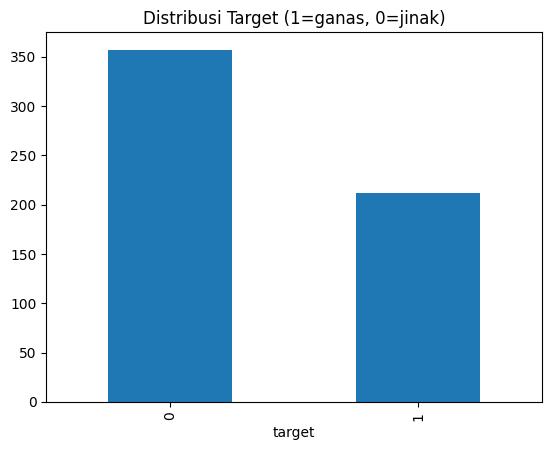

In [4]:
# Distribusi target (cek imbalance)
print(df["target"].value_counts())
print(df["target"].value_counts(normalize=True).round(3))
df["target"].value_counts().plot(kind="bar", title="Distribusi Target (1=ganas, 0=jinak)")
plt.show()

worst concave points    0.793566
worst perimeter         0.782914
mean concave points     0.776614
worst radius            0.776454
mean perimeter          0.742636
worst area              0.733825
mean radius             0.730029
mean area               0.708984
mean concavity          0.696360
worst concavity         0.659610
Name: target, dtype: float64


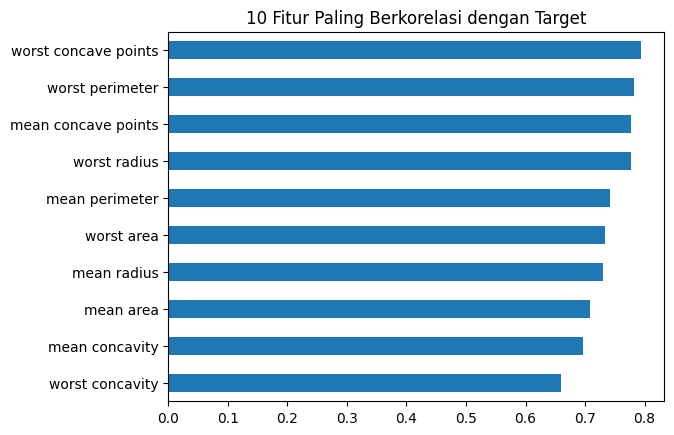

In [5]:
# Korelasi fitur dengan target
korelasi = df.corr()["target"].drop("target").sort_values(ascending=False)
print(korelasi.head(10))
korelasi.head(10).plot(kind="barh", title="10 Fitur Paling Berkorelasi dengan Target")
plt.gca().invert_yaxis(); plt.show()

## 3. Data Preparation

### Missing value

In [6]:
print("Total missing value:", df.isna().sum().sum())

Total missing value: 0


### Outlier (metode IQR)

In [7]:
fitur_semua = df.drop(columns=["target"]).columns
Q1, Q3 = df[fitur_semua].quantile(0.25), df[fitur_semua].quantile(0.75)
IQR = Q3 - Q1
outlier = ((df[fitur_semua] < Q1 - 1.5*IQR) | (df[fitur_semua] > Q3 + 1.5*IQR)).sum()
print(outlier.sort_values(ascending=False).head(10))

area error                 65
radius error               38
perimeter error            38
worst area                 35
smoothness error           30
fractal dimension error    28
compactness error          28
symmetry error             27
mean area                  25
worst fractal dimension    24
dtype: int64


In [8]:
FITUR = ["worst radius", "worst concave points", "mean texture", "mean smoothness", "area error"]
print(df[FITUR].corrwith(df["target"]).round(3))

worst radius            0.776
worst concave points    0.794
mean texture            0.415
mean smoothness         0.359
area error              0.548
dtype: float64


## Praktikum 14.2 Import Dataset dan Preprocessing

In [9]:
X = df[FITUR]
y = df["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y,
    test_size=0.2, stratify=y, random_state=42)
print(X_train.shape, X_test.shape)

(455, 5) (114, 5)


## 14.11 Training & Tuning (Komparasi 3 Model)

In [10]:
model_configs = {
    "Random Forest": (RandomForestClassifier(random_state=42),
        {"n_estimators": [100, 300], "max_depth": [5, 10, None]}),
    "Gradient Boosting": (GradientBoostingClassifier(random_state=42),
        {"n_estimators": [100, 200], "learning_rate": [0.05, 0.1]}),
    "SVM": (Pipeline([("scaler", StandardScaler()), ("svm", SVC(probability=True))]),
        {"svm__C": [1, 10], "svm__gamma": [0.01, 0.1]}),
}

In [11]:
hasil_terbaik = {}
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for nama, (model, params) in model_configs.items():
    search = RandomizedSearchCV(model, params, n_iter=4, cv=skf,
        scoring="f1", random_state=42)
    search.fit(X_train, y_train)
    hasil_terbaik[nama] = search.best_estimator_
    print(f"{nama}: F1 CV terbaik = {search.best_score_:.3f}, params = {search.best_params_}")

Random Forest: F1 CV terbaik = 0.944, params = {'n_estimators': 100, 'max_depth': 5}
Gradient Boosting: F1 CV terbaik = 0.944, params = {'n_estimators': 100, 'learning_rate': 0.05}
SVM: F1 CV terbaik = 0.951, params = {'svm__gamma': 0.01, 'svm__C': 10}


## 14.12 Evaluasi dan Pemilihan Model Terbaik

In [12]:
rekap = []
for nama, model in hasil_terbaik.items():
    pred = model.predict(X_test)
    rekap.append({"Model": nama,
                  "F1 Test": f1_score(y_test, pred),
                  "Recall Test": recall_score(y_test, pred)})
    print(f"{nama}: F1-Score Test = {f1_score(y_test, pred):.3f}")
rekap = pd.DataFrame(rekap).sort_values("F1 Test", ascending=False)
rekap

Random Forest: F1-Score Test = 0.950
Gradient Boosting: F1-Score Test = 0.914
SVM: F1-Score Test = 0.938


,Model,F1 Test,Recall Test
0,Random Forest,0.950000,0.904762
2,SVM,0.938272,0.904762
1,Gradient Boosting,0.913580,0.880952


In [13]:
# Pilih model terbaik berdasarkan F1 test (sesuaikan dengan analisis Anda)
nama_terpilih = rekap.iloc[0]["Model"]
model_terpilih = hasil_terbaik[nama_terpilih]
print("Model terpilih:", nama_terpilih)
print(classification_report(y_test, model_terpilih.predict(X_test),
      target_names=["Jinak", "Ganas"]))
print(confusion_matrix(y_test, model_terpilih.predict(X_test)))

Model terpilih: Random Forest
              precision    recall  f1-score   support

       Jinak       0.95      1.00      0.97        72
       Ganas       1.00      0.90      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.95      0.96       114
weighted avg       0.97      0.96      0.96       114

[[72  0]
 [ 4 38]]


## 14.13 Serialisasi Model untuk Deployment

In [14]:
joblib.dump(model_terpilih, "model_terbaik.pkl")
print("Model berhasil disimpan sebagai model_terbaik.pkl")

Model berhasil disimpan sebagai model_terbaik.pkl


## 14.14 Aplikasi Deployment Sederhana (Streamlit)

In [15]:
# Cek bahwa model yang disimpan bisa dimuat dan dipakai seperti di aplikasi
model_load = joblib.load("model_terbaik.pkl")
contoh = pd.DataFrame([[15.0, 0.10, 18.0, 0.10, 30.0]], columns=FITUR)
print("Prediksi:", model_load.predict(contoh)[0])
print("Probabilitas ganas:", round(model_load.predict_proba(contoh)[0][1], 3))

Prediksi: 0
Probabilitas ganas: 0.025


## 14.15 Interpretasi
